# Center-bearing, center-distance, and theta analysis

Analyze one recording using saved tracking, spikes, arena geometry, and LFP.

- **Center bearing (CB):** direction of the arena center relative to the head.
- **Center distance (CD):** distance from the animal to the arena center.
- **Head direction (HD):** head orientation in arena coordinates.
- **Theta:** spike rhythmicity, LFP phase locking, and a phase-precession candidate test.

Use the remote `rfmapping` kernel on `hhw9l84`. Run from a fresh kernel after changing recordings.

In [1]:
%matplotlib inline

from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import false_discovery_control

from EBB.center_cell_io import (
    file_evidence,
    load_center_session,
    load_lfp,
    load_motive_center_session,
    save_center_analysis,
)
from EBB.center_cell_plotting import (
    plot_behavior,
    plot_center_unit,
    plot_lfp_reference,
    plot_theta_unit,
)
from EBB.center_cells import (
    CenterCellConfig,
    analyze_center_cells,
    analyze_center_theta,
    behavior_intervals,
    prepare_center_behavior,
)
from Utils.plotting import apply_light_plot_style
from Utils.theta_analysis import extract_theta_phase, summarize_lfp_reference

apply_light_plot_style()

## Recording and parameters

Set `is_motive` explicitly: `True` uses Motive tracking and circular geometry; `False` uses Basler tracking and rectangular geometry.

All good units are analyzed. `unit_id` selects the unit shown in the figures.

In [2]:
recording_root = Path("/mnt/senzailab/Kai/#Recording/m20")
date = "260918"
recording_number = 11
probe_name = "A"
phase_key = "baseline"
is_motive = False

unit_id = 194
lfp_channel = 0  # Zero-based probe channel used as the LFP reference.
n_shuffles = 100
shuffle_seed = 20261019
config = CenterCellConfig()

session_id = f"{recording_root.name}_{date}_{recording_number}"
session_dir = recording_root / date / f"{date}_{recording_number}"
lfp_path = (
    session_dir / "data" / "lfp" / f"Probe{probe_name}"
    / phase_key / f"channel{lfp_channel}.npz"
)

## Load and prepare behavior

Read the saved inputs for the selected recording. Missing files stop loading.

The default movement threshold is >2.5 cm/s. Excluded frames and tracking gaps contribute no occupancy. CB and HD increase clockwise: CB 0° is forward; HD 0° is up in arena coordinates.

In [3]:
if is_motive:
    session_data = load_motive_center_session(
        session_dir, probe=probe_name, phase=phase_key,
    )
else:
    session_data = load_center_session(
        session_dir, probe=probe_name, phase=phase_key,
    )

In [4]:
behavior = prepare_center_behavior(
    session_data["times_s"],
    session_data["xy_cm_y_down"],
    session_data["hd_cw_deg"],
    session_data["arena_size_cm"],
    valid_mask=session_data["valid_mask"],
    arena_shape="circle" if is_motive else "rectangle",
    config=config,
)

In [5]:
session_summary = pd.Series(
    {
        "good_units": len(session_data["spikes_by_unit"]),
        "duration_s": np.diff(behavior["trial_interval_s"])[0],
        "moving_time_s": behavior["exposure_s"][behavior["moving_mask"]].sum(),
        "spatial_coverage": behavior["spatial_coverage"],
        "excluded_tracking_fraction": session_data["tracking_selection"]["excluded_fraction"],
    },
    name=session_id,
)

findfont: Failed to find font weight medium, now using 400.


findfont: Failed to find font weight medium, now using 400.


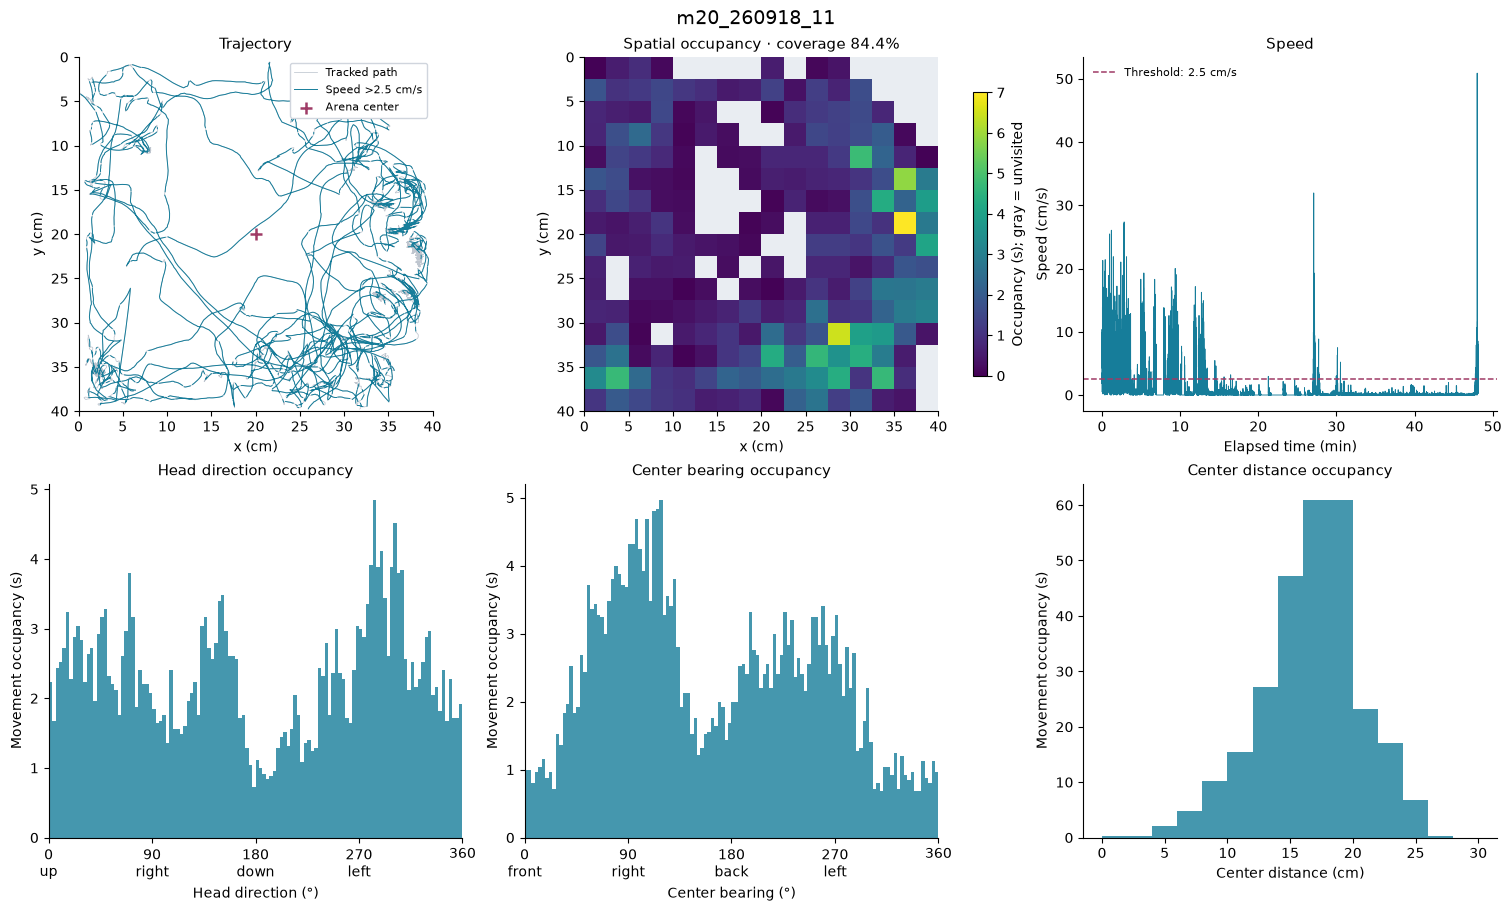

In [6]:
fig = plot_behavior(behavior, title=session_id)
display(fig)
plt.close(fig)

## Center and head-direction tuning

Firing rate is spike count divided by occupancy in each angle or distance bin. CB and HD use mean vector length (MVL); CD uses the R² of a linear fit to unsmoothed rates. Stability is the correlation between the first and second halves of the recording.

With the default parameters, classification requires >100 movement spikes and >80% spatial coverage. CB and HD also require all angle bins to be visited. Strength and stability must each exceed the 99th percentile of their shuffle distributions, pooled across eligible units in this recording. Unassessed units retain NA labels.

In [7]:
center_results = analyze_center_cells(
    behavior,
    session_data["spikes_by_unit"],
    n_shuffles=n_shuffles,
    seed=shuffle_seed,
)
center_summary = center_results["summary"]

In [8]:
classification_counts = {}
for feature in ("cb", "cd", "hd"):
    labels = center_summary[f"{feature}_is_cell"]
    classification_counts[feature.upper()] = {
        "positive": int(labels.sum()),
        "assessed": int(labels.notna().sum()),
        "unassessed": int(labels.isna().sum()),
    }
classification_counts = pd.DataFrame.from_dict(classification_counts, orient="index")

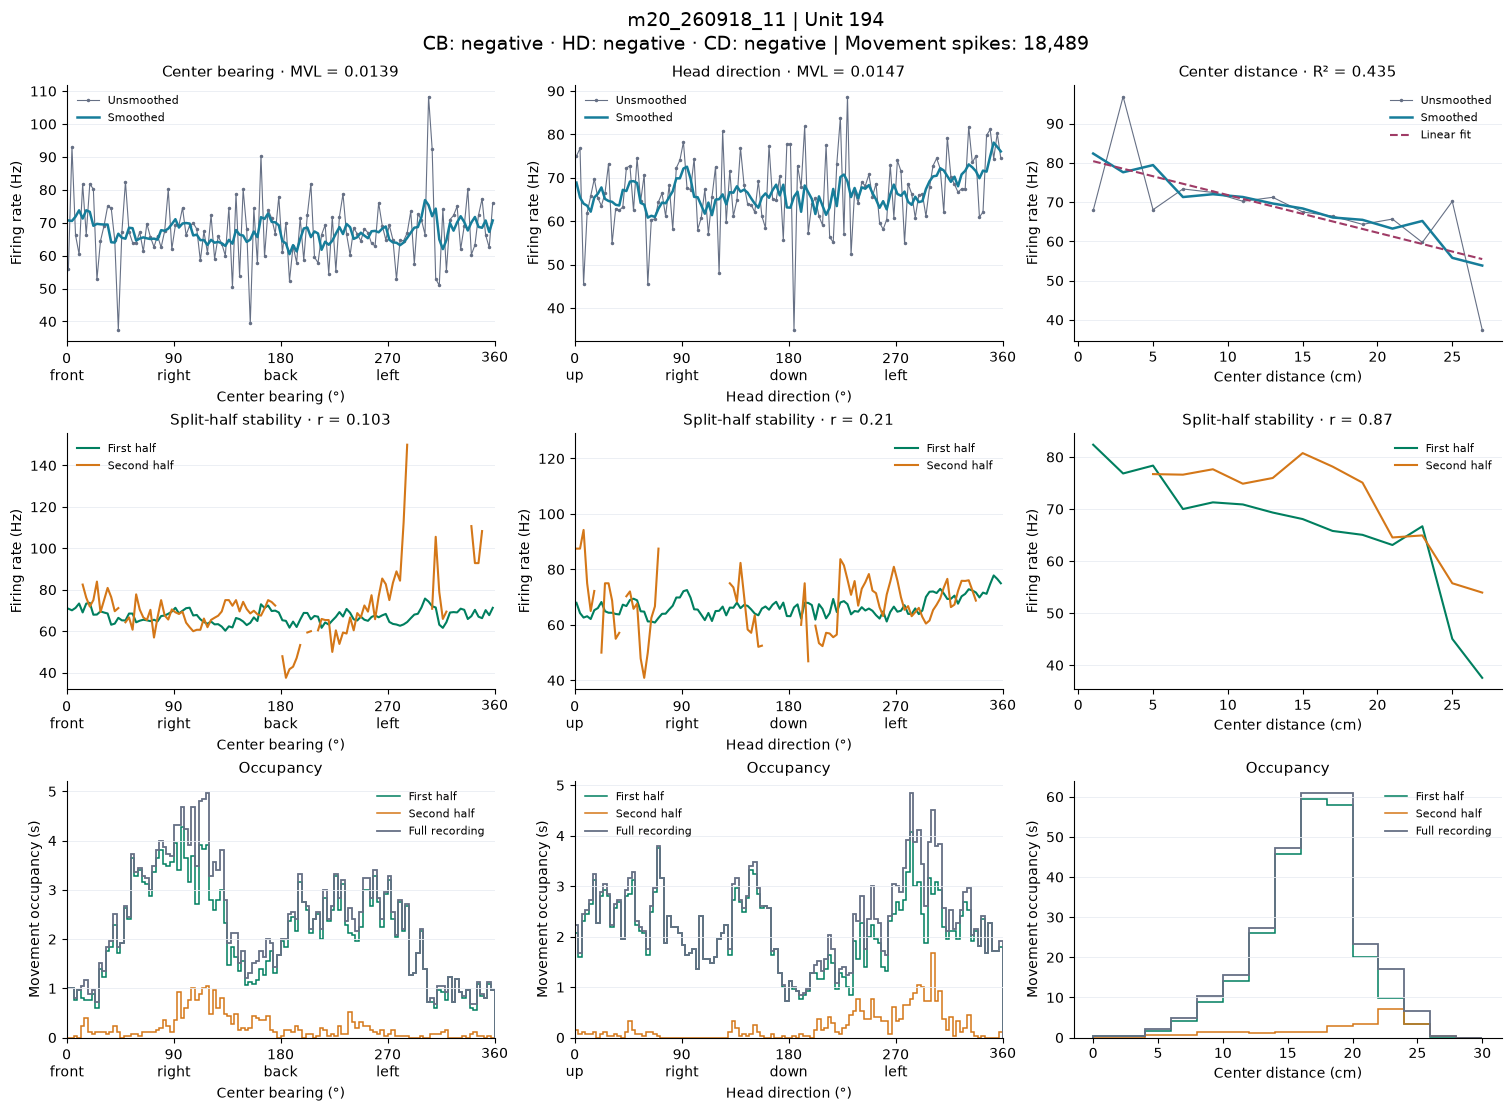

In [9]:
fig = plot_center_unit(
    center_results, unit_id, title=f"{session_id} | Unit {unit_id}",
)
display(fig)
plt.close(fig)

## LFP reference

Load the saved LFP and extract phase from the 5–10 Hz signal. The reference plot shows the full-recording power spectrum and a five-second excerpt centered on the longest movement interval.

LFP phase 0° is the positive peak. The selected probe channel is a local reference; its anatomical source must be established separately.

In [10]:
lfp = load_lfp(lfp_path)

In [11]:
theta_phase = extract_theta_phase(
    lfp["times_s"],
    lfp["voltage_uv"],
    sample_rate_hz=lfp["sample_rate_hz"],
)
moving_intervals = behavior_intervals(behavior, behavior["moving_mask"])
lfp_reference = summarize_lfp_reference(lfp, theta_phase, moving_intervals)
lfp_metadata = lfp["metadata"]
del lfp

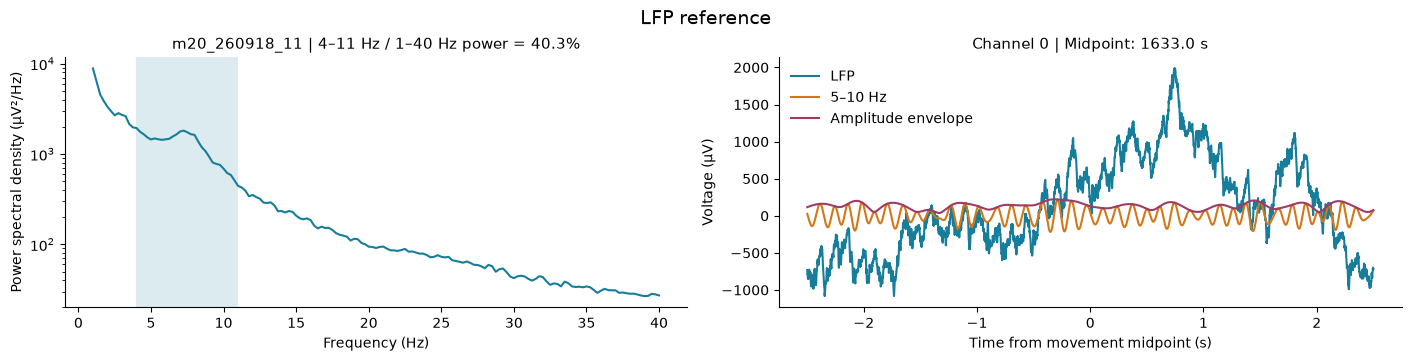

In [12]:
fig = plot_lfp_reference({session_id: lfp_reference}, channel=lfp_channel)
display(fig)
plt.close(fig)

## Theta analysis

- **Rhythmicity:** the spike autocorrelogram (ACG) has a 4–11 Hz spectral peak with theta rhythmicity index (TRI) ≥5.
- **Phase locking:** report phase MVL, Rayleigh p, and Benjamini–Hochberg q across assessed units. The classification uses raw p <0.01.
- **Phase precession:** an exploratory spectral test for spike rhythmicity faster than the LFP. This is not a position–phase regression.

ACG pairs stay within continuous tracking or LFP intervals. Phase occupancy uses the same movement selection as the spikes. Spike-count and spatial-coverage requirements also apply to theta classification.

In [13]:
theta_results = analyze_center_theta(
    behavior, session_data["spikes_by_unit"], theta_phase,
)
theta_summary = theta_results["summary"]

In [14]:
assessed = (
    theta_summary["is_phase_locked"].notna()
    & theta_summary["rayleigh_p"].notna()
)
theta_summary["rayleigh_q_bh"] = np.nan
if assessed.any():
    theta_summary.loc[assessed, "rayleigh_q_bh"] = false_discovery_control(
        theta_summary.loc[assessed, "rayleigh_p"].to_numpy(),
        method="bh",
    )

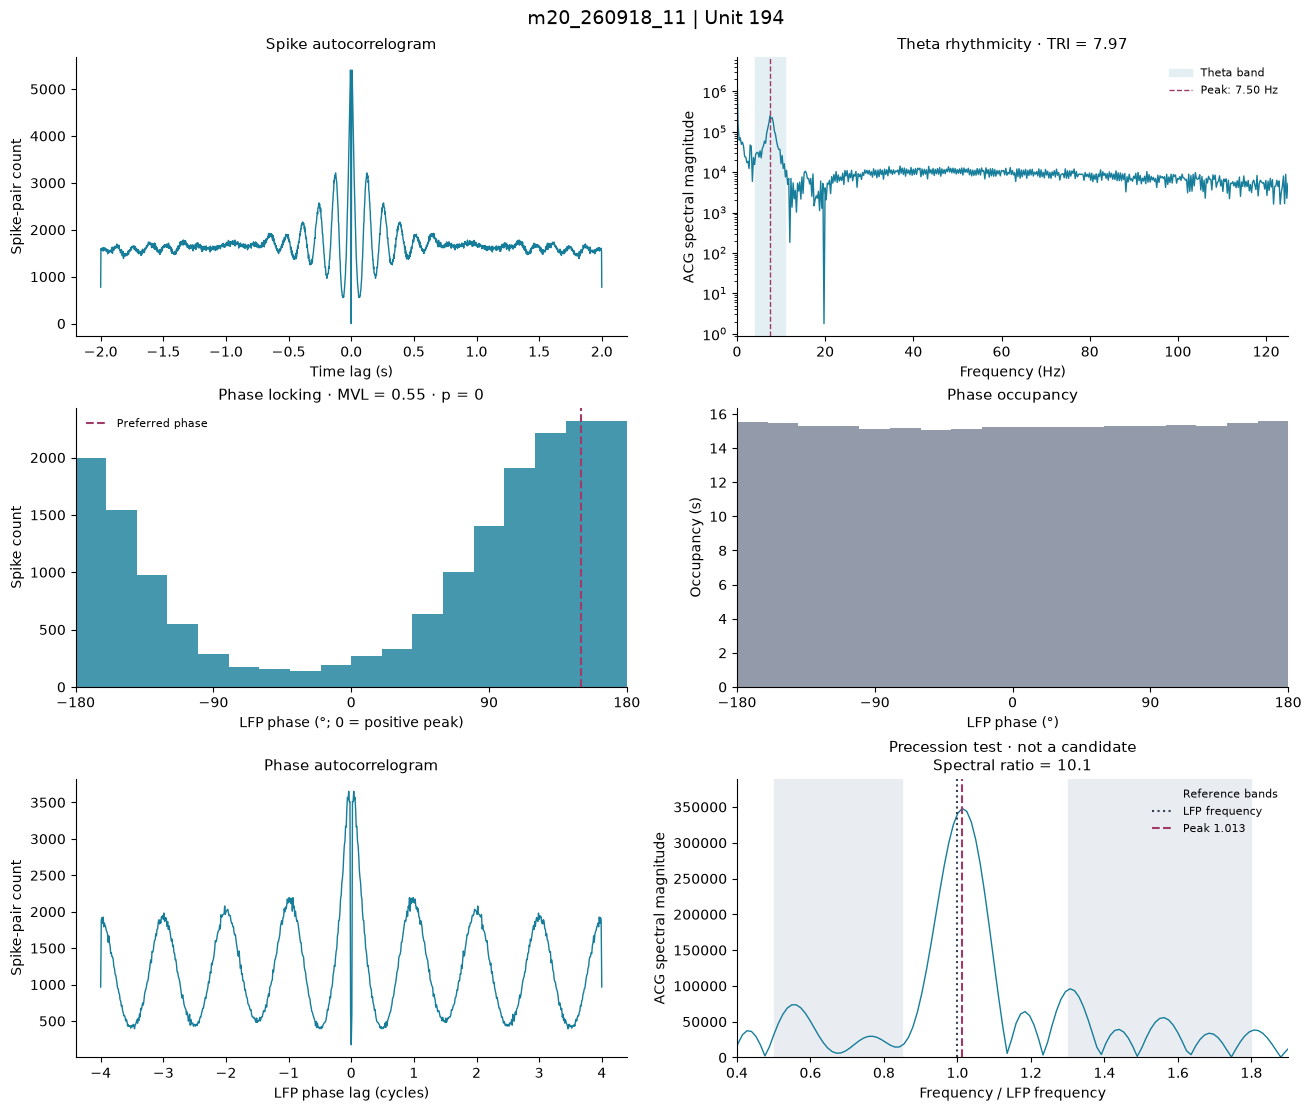

In [15]:
fig = plot_theta_unit(
    theta_results["units"][unit_id],
    title=f"{session_id} | Unit {unit_id}",
)
display(fig)
plt.close(fig)

## Save results

Save tables, raw counts, occupancy, shuffle statistics, and source metadata in a new timestamped directory. Existing runs remain available; unassessed classifications remain NA.

In [16]:
unit_summary = center_summary.reset_index(drop=True).merge(
    theta_summary.reset_index(drop=True),
    on="unit_id",
    validate="one_to_one",
)
geometry = {
    "arena_shape": behavior["arena_shape"],
    "arena_size_cm": behavior["arena_size_cm"].tolist(),
}
if is_motive:
    geometry.update(session_data["geometry"])

theta_results["metadata"].update(
    reference_channel=lfp_channel,
    lfp_source=lfp_metadata,
)
provenance = {
    "session_id": session_id,
    "is_motive": is_motive,
    "input_files": session_data["provenance"],
    "geometry": geometry,
    "tracking_selection": session_data["tracking_selection"],
    "behavior_metadata": behavior["metadata"],
    "lfp_file": file_evidence(lfp_path),
}

In [17]:
output_dir = (
    Path("output/cb_cd_theta") / session_id
    / datetime.now().strftime("%Y%m%d_%H%M%S")
)
save_center_analysis(
    output_dir,
    center_results,
    theta_results=theta_results,
    provenance=provenance,
)
unit_summary.to_csv(output_dir / "cells.csv", index=False)
session_summary.to_csv(output_dir / "session_qc.csv")
classification_counts.to_csv(output_dir / "classification_counts.csv")
pd.Series(lfp_reference["summary"]).to_csv(output_dir / "lfp_reference_qc.csv")
print(f"Saved results to {output_dir.resolve()}")

Saved results to /home/kai/Developer/rfmapping/output/cb_cd_theta/m20_260918_11/20261020_163731


## Generate an LFP cache

Run this step separately when the selected LFP file does not exist. The generator reads Open Ephys data, downsamples to 1 kHz, and aligns the signal to the behavior clock. Saving refuses to replace an existing file.

```python
from EBB.center_cell_io import generate_lfp_from_open_ephys, save_lfp

lfp = generate_lfp_from_open_ephys(
    session_dir,
    probe=probe_name,
    channel=lfp_channel,
    interval_s=behavior["trial_interval_s"],
    adc_time_origin_s=session_data["adc_time_origin_s"],
)
save_lfp(lfp_path, lfp)
del lfp
```

Methods: [Long et al.](https://doi.org/10.1038/s41467-024-54699-9). Shuffle thresholds use eligible units from this recording. ACG and phase-precession parameters are recorded in the saved metadata.